# TORCS Training and Validation Tracks - Visualizing the Curvature

In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

from gym_torcs.curvature import RacingLineCurvatureMap
from gym_torcs.constants import MAX_CURVATURE, RACING_LINE_DIR

In [2]:
TRACKS = {
    "alpine-1": "Alpine-1 (Training)",
    "alpine-2": "Alpine-2 (Validation)",
    "g-track-2": "G-Track-2 (Validation)",
    "street-1": "Street-1 (Training)",
    "aalborg": "Aalborg (Training)",
    "forza": "Forza (Training)",
    "brondehach": "Brondehach (Validation)",
    "wheel-1": "wheel-1 (Training)",
    "wheel-2": "wheel-2 (Training)",

}

TRACK_ORDER = [
    # Training tracks 
    "alpine-1",
    "aalborg",
    "street-1",
    "forza",
    "wheel-1",
    "wheel-2",

    # Validation tracks
    "g-track-2",
    "brondehach",
    "alpine-2",
]

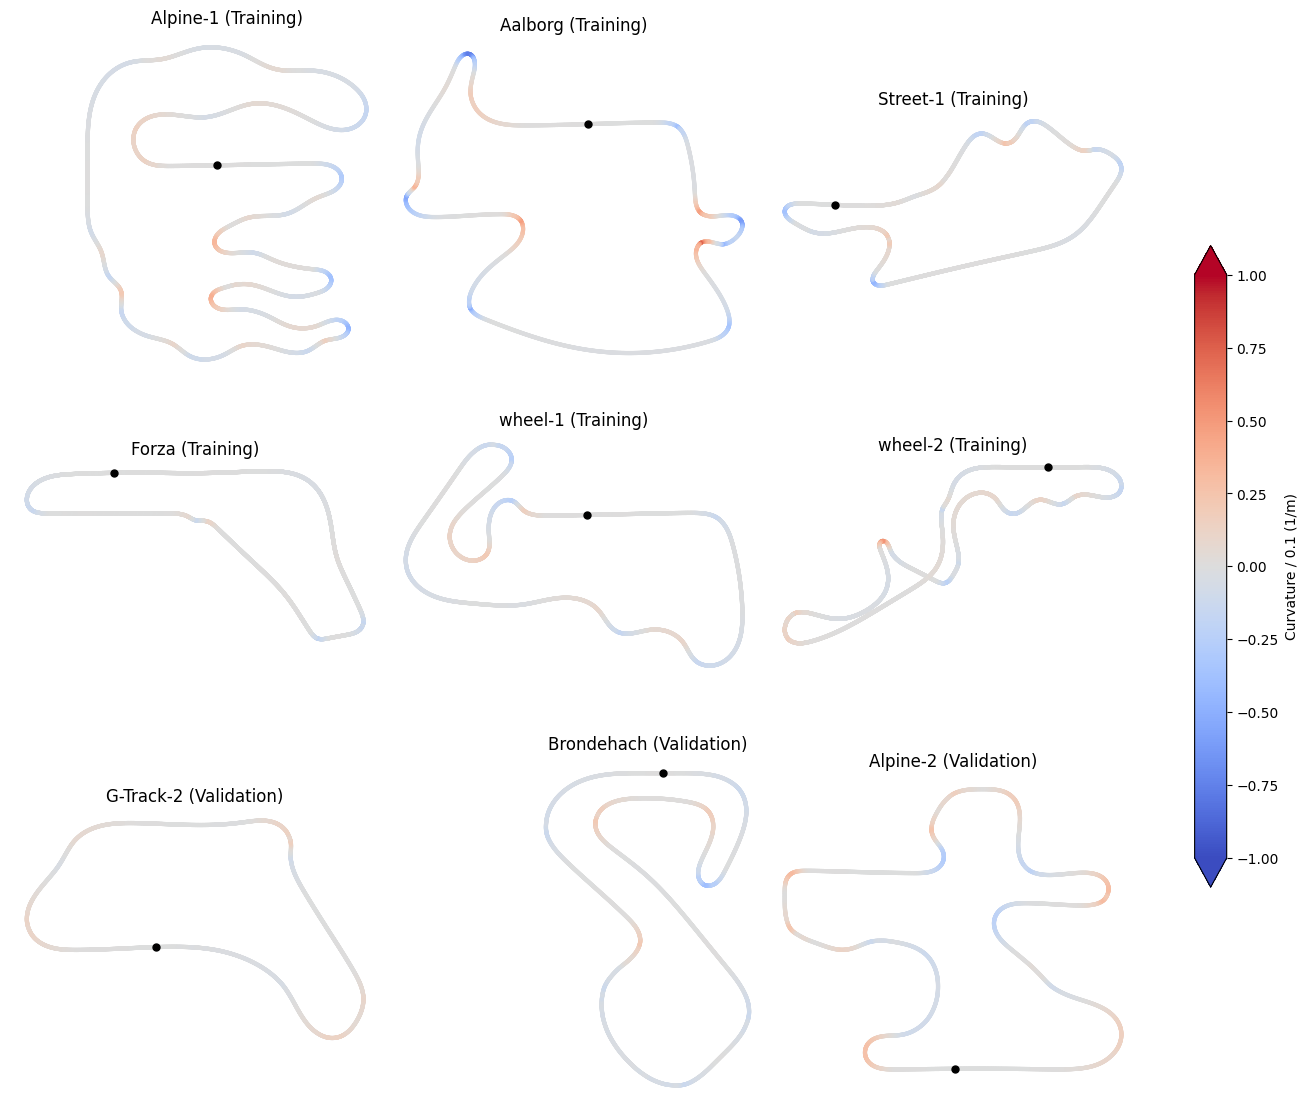

: 

In [ ]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(13, 11), layout="constrained")
# Curvature is signed (left vs. right turns), so use a diverging map centred at 0
# and the same scale for every track. Values are normalised by MAX_CURVATURE as in the env.
norm = TwoSlopeNorm(vmin=-1.0, vcenter=0.0, vmax=1.0)

scatter = None
for track_name, ax in zip(TRACK_ORDER, axes.flat):
    title = TRACKS[track_name] 
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.axis("off")

    path = RACING_LINE_DIR / f"{track_name}.csv"
    if not path.exists():
        ax.text(0.5, 0.5, f"missing {path.name}", ha="center", va="center", transform=ax.transAxes)
        continue

    line = RacingLineCurvatureMap.from_csv(path)
    curvature = line.curvature / MAX_CURVATURE
    scatter = ax.scatter(line.x, line.y, c=curvature, cmap="coolwarm", norm=norm, s=4)
    # Mark the start/finish line.
    ax.plot(line.x[0], line.y[0], marker="o", color="black", markersize=5)

if scatter is not None:
    cbar = fig.colorbar(scatter, ax=axes, shrink=0.6, extend="both")
    cbar.set_label(f"Curvature / {MAX_CURVATURE} (1/m)")

plt.show()